In [1]:

# Import libraries for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:


!pip install -q scikit-learn

from sklearn.datasets import fetch_california_housing
import pandas as pd

housing = fetch_california_housing(as_frame=True)

df = housing.frame

# Display the first five rows
df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:

#A quick look at our dataset
print("Dataset shape:", df.shape)

# Check the columns and their data types
print("\nDataset information:")
df.info()

# See if any values are missing
print("\nMissing values:")
print(df.isnull().sum())

# Get a basic statistical summary of the data
print("\nSummary of the dataset:")
display(df.describe())


Dataset shape: (20640, 9)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Summary of the dataset:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


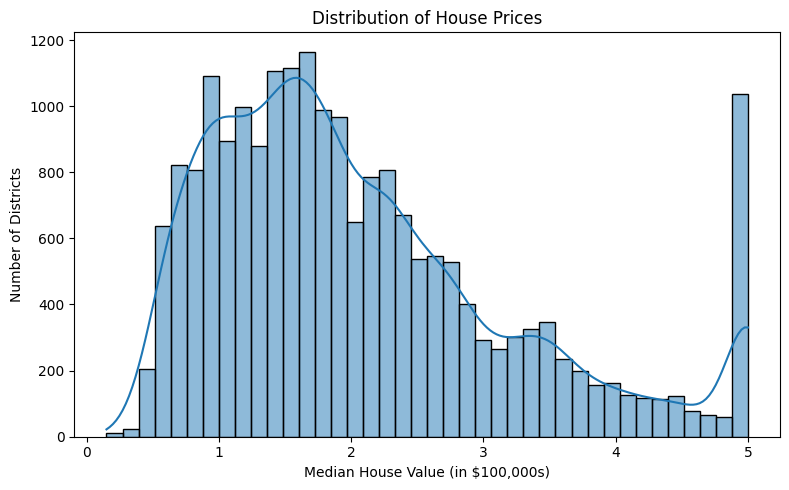

In [4]:

# Let's see how house prices are spread across the dataset
plt.figure(figsize=(8, 5))
sns.histplot(df["MedHouseVal"], bins=40, kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("Median House Value (in $100,000s)")
plt.ylabel("Number of Districts")
plt.tight_layout()
plt.show()


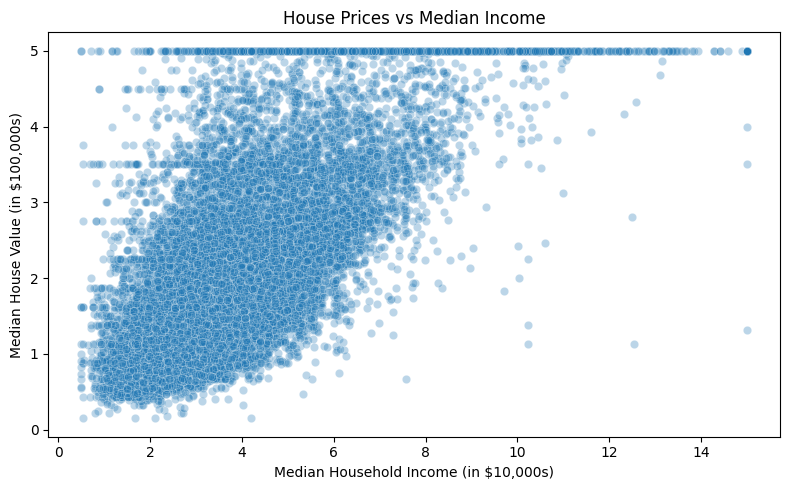

In [5]:

# Let's check how income is related to house prices
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="MedInc", y="MedHouseVal", alpha=0.3)

plt.title("House Prices vs Median Income")
plt.xlabel("Median Household Income (in $10,000s)")
plt.ylabel("Median House Value (in $100,000s)")
plt.tight_layout()
plt.show()


In [6]:

from sklearn.model_selection import train_test_split
# Separate the house details from the prices we want to predict
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]
# Keep some data aside to test the model later
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (16512, 8)
Testing data: (4128, 8)


In [7]:

from sklearn.linear_model import LinearRegression
# Train the model using our training data
model = LinearRegression()
model.fit(X_train, y_train)
print("Linear Regression model trained successfully!")


Linear Regression model trained successfully!


In [8]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Let's see how well our model predicts house prices
y_pred = model.predict(X_test)
# Compare the predicted prices with the actual prices
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", round(mae, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))
print("R-squared Score (R²):", round(r2, 3))


Mean Absolute Error (MAE): 0.533
Root Mean Squared Error (RMSE): 0.746
R-squared Score (R²): 0.576


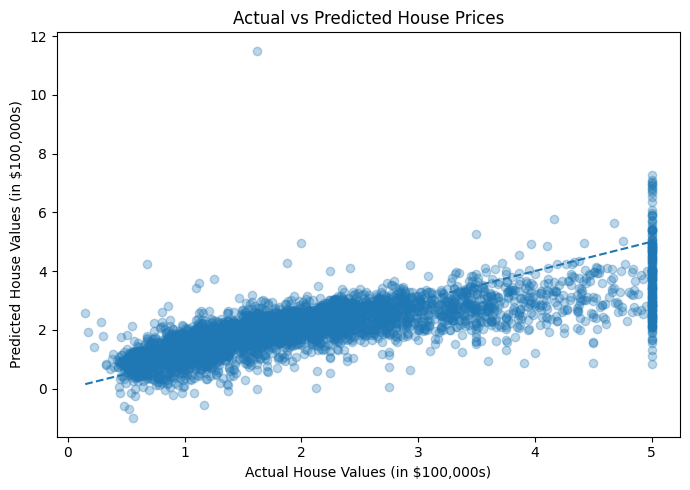

In [9]:

# Let's compare the actual prices with our predictions
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--")
plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Values (in $100,000s)")
plt.ylabel("Predicted House Values (in $100,000s)")
plt.tight_layout()
plt.show()


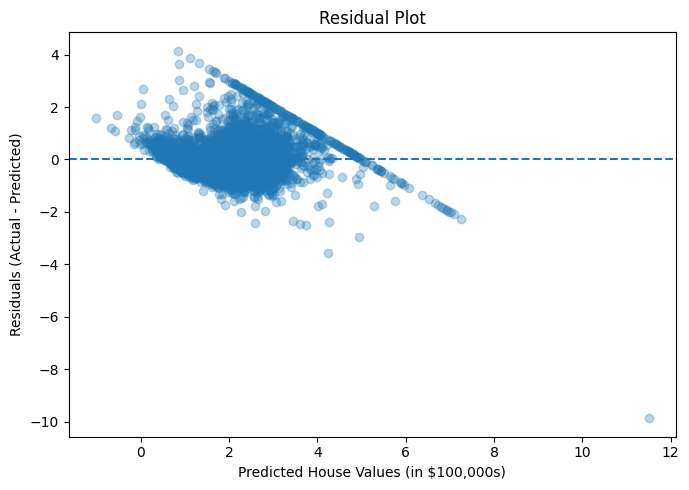

In [10]:

# Let's check how far our predictions are from the actual values
residuals = y_test - y_pred

plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, linestyle="--")

plt.title("Residual Plot")
plt.xlabel("Predicted House Values (in $100,000s)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.tight_layout()
plt.show()


In [11]:

# Let's compare one actual house value with its predicted value
sample_house = X_test.iloc[[0]]
actual_price = y_test.iloc[0]
predicted_price = model.predict(sample_house)[0]

print("Actual house value: $", round(actual_price * 100000, 2))
print("Predicted house value: $", round(predicted_price * 100000, 2))


Actual house value: $ 47700.0
Predicted house value: $ 71912.28


## Conclusion

In this project, I built a Linear Regression model to predict house values using the California Housing dataset. I explored the dataset, checked for missing values, visualized the distribution of house prices, and studied the relationship between median income and house values.

The dataset contained 20,640 records and eight input features. I split the data into training and testing sets, trained the model, and evaluated its performance using MAE, RMSE, and R².

The model achieved an MAE of 0.533, an RMSE of 0.746, and an R² score of 0.576. These results show that the model captures some of the variation in house values, although its predictions still have room for improvement.

This project helped me understand the basic machine learning workflow, including data exploration, model training, prediction, and evaluation. It also showed me the importance of examining prediction errors and understanding the limitations of a dataset.
